# **Folding thermodynamics from a molecular dynamics simulation: the GDNP β-turn**

*Utrecht University Molecular Modelling courses from the [Bonvin lab](https://bonvinlab.org).*

The other MD notebooks in this repository **run** a simulation. This one **analyses** one — a
real, all-atom simulation of the tetrapeptide **Gly-Asp-Asn-Pro (GDNP)** in explicit water,
run at five temperatures (280, 300, 320, 340 and 360 K). The data come from the study:

> F.J. Fuchs, A.M.J.J. Bonvin, B. Bochicchio, A. Pepe, A.J.P. Alix and A.M. Tamburro.
> **Kinetics and thermodynamics of type VIII β-turn formation: a CD, NMR and microsecond explicit
> molecular dynamics study of the GDNP tetrapeptide.** *Biophys. J.* **90**, 2745–2759 (2006).

Molecular dynamics integrates Newton's equations of motion for every atom of the system, so its
output is a **trajectory**: the structure as a function of time. Simulations of large proteins in
water now reach tens of microseconds — enough for pico- to microsecond dynamics and small
conformational changes, but not for protein folding, which takes milliseconds and longer. A
peptide of four residues, however, folds and unfolds **hundreds of times** in a hundred
nanoseconds. That is enough sampling to measure **thermodynamics** directly: by simply *counting*
how often the peptide is folded, we can extract the free energy, enthalpy and entropy of folding.

GDNP is known to form a **type VIII β-turn**: the chain reverses direction so that the
Cα atoms of residue 1 (Gly) and residue 4 (Pro) come close together. We follow a single number
along the trajectory — the **Cα(i)–Cα(i+3) distance** between those two atoms:

* **turn** (folded): the ends are close, distance roughly 0.5–0.7 nm;
* **extended** (unfolded): the ends are apart, distance roughly 0.9–1.05 nm.

### What you will do

1. read the simulation data and **plot the distance** as a function of time;
2. **choose a cutoff** that separates "turn" from "extended" *(your decision)*;
3. **count** the two populations and turn them into a free energy of folding, $\Delta G$;
4. repeat at every temperature and extract the **enthalpy** $\Delta H$ and **entropy** $\Delta S$ of folding;
5. ask **how long is long enough**: how $\Delta G$, $\Delta H$
   and $\Delta S$ converge with simulation time, how large their **statistical errors** are, and whether the
   odd-looking 320 K point is really an outlier;
6. look at the **kinetics**: how long a turn lasts, the folding and unfolding rates, and their
   activation energies.

The notebook contains **four exercises** in which you make a choice or write a short function
(the stubs are marked `# <-- your code here`). The notebook runs from top to bottom **before** you
fill anything in: cells that need your answer simply print what is missing. Worked solutions are
hidden in folded **"worked solution"** blocks — try first, then check.

> **Solutions version — for instructors / checking only.** Every exercise is filled in with
> its worked solution (`CUTOFF = 0.70` nm) and the solution blocks are
> unfolded, so all figures and numbers can be compared with the solution text.
> The student version is `Notebooks/MD-analysis-GDNP.ipynb`.

---
## **1. Theory: from populations to thermodynamics**

### A two-state model

Treat the peptide as a molecule with two states, **extended** (E) and **turn** (T), in equilibrium:

$$\text{E} \;\rightleftharpoons\; \text{T}, \qquad K \;=\; \frac{P_\text{turn}}{P_\text{extended}}$$

where $P$ is the probability of finding the peptide in that state. A long enough MD trajectory
samples the equilibrium (Boltzmann) distribution, so the probability of a state is simply **the
fraction of the frames in which the peptide is in that state.** The free energy of folding then
follows from the equilibrium constant:

$$\boxed{\;\Delta G_\text{folding} \;=\; -RT\,\ln\frac{P_\text{turn}}{P_\text{extended}}\;}$$

with $R = 8.314\ \text{J mol}^{-1}\text{K}^{-1}$ the gas constant. Note the sign convention:

* $P_\text{turn} > P_\text{extended}$ $\Rightarrow$ $\Delta G < 0$ — folding is favourable;
* $P_\text{turn} < P_\text{extended}$ $\Rightarrow$ $\Delta G > 0$ — the turn is the minority state;
* every factor 10 in the population ratio is worth $RT\ln 10 \approx 5.7$ kJ/mol at 300 K.

### Enthalpy and entropy from the temperature dependence

The free energy has an enthalpic and an entropic part,

$$\Delta G(T) \;=\; \Delta H \;-\; T\,\Delta S .$$

If $\Delta H$ and $\Delta S$ do not themselves depend on temperature over the range studied (i.e.
the heat capacity change $\Delta C_p \approx 0$), **$\Delta G$ is a straight line in $T$**:

* its **slope** is $-\Delta S$, so $\Delta S = -\,\mathrm{d}\Delta G/\mathrm{d}T$;
* its **intercept** at $T=0$ is $\Delta H$.

So: measure $\Delta G$ at several temperatures, fit a line, read off $\Delta H$ and $\Delta S$.
Each simulation was run independently at its own temperature, so each gives one point on that line.

### The catch: counting needs a definition

Nothing in the simulation says "this frame is a turn". *We* have to decide, from the distance,
which frames count as folded — and as you will see, that decision affects the answer.

## **Showing and hiding the code**

The Python that only draws figures is a means to an end, so **those cells start collapsed**: you
see the figure, not the matplotlib that made it. Nothing is disabled — a collapsed cell runs
exactly like an open one. The cells you need to read or edit are left open.

* **One cell:** click the blue **collapser bar** just left of it (or *View → Collapse Selected Code*).
* **All of them:** *View → Collapse All Code* / *Expand All Code*.

---
## **2. Imports**

Only **numpy** and **matplotlib** are needed; the cell installs them if missing, so the notebook
also runs on Google Colab and in the browser (JupyterLite).

In [1]:
# --- Install required packages (works locally, on Colab, and on JupyterLite) ---
%pip install -q matplotlib numpy

from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import sys, warnings
if sys.platform == "emscripten":   # JupyterLite: its matplotlib build warns on every text label
    warnings.filterwarnings("ignore", message=r"The \w+ parameter as float was deprecated")
%matplotlib inline

# one fixed colour per temperature (used in every figure), plus two for the two runs
T_COLOR = {280: "#2a78d6", 300: "#eb6834", 320: "#1baf7a", 340: "#eda100", 360: "#e87ba4"}
C_RUN = "#1c5cab"                         # dark blue = the simulation data
C_TURN, C_EXT = "#d55181", "#2a78d6"      # turn / extended states
C_REF = "#8a8a8a"

plt.rcParams.update({
    "figure.dpi": 110,
    "axes.grid": True, "grid.alpha": 0.25, "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlesize": 11, "axes.labelsize": 10,
    "legend.frameon": False, "legend.fontsize": 9,
    "lines.linewidth": 1.6,
})


def works(f, *args):
    '''True once f(*args) returns real numbers instead of the NaN placeholder.'''
    try:
        return bool(np.all(np.isfinite(np.asarray(f(*args), dtype=float))))
    except Exception:
        return False


[notice] A new release of pip is available: 26.1.1 -> 26.2.1
[notice] To update, run: /Users/abonvin/haddock_git/haddock3/.venv-3.14/bin/python3.14 -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.


---
## **Python you will need**

You do not need to be a Python expert for the exercises: each one needs only a few lines, and the
code cells contain step-by-step hints. These are the building blocks — run the cell below to see
each one in action, and come back here when a hint mentions one of them.

| what | example | result |
|---|---|---|
| a numpy **array** of numbers | `x = np.array([0.5, 0.9, 0.6])` | |
| compare every element at once → `True`/`False` | `x < 0.7` | `[True, False, True]` |
| `True` counts as 1, `False` as 0, so the **mean** is a fraction | `np.mean(x < 0.7)` | `0.667` |
| arithmetic works on whole arrays, element by element | `1 - x`,  `x / (1 - x)` | `[0.5, 0.1, 0.4]`, … |
| natural logarithm ($\ln$) | `np.log(x)` | (`np.log10` is base 10 — not what we want) |
| **running** (cumulative) sum | `np.cumsum([1, 0, 1, 1])` | `[1, 1, 2, 3]` |
| the numbers 1, 2, …, n | `np.arange(1, n + 1)` | |
| number of elements | `len(x)` | `3` |
| one column of a 2-D array | `d130[:, 0]` | all distances at 280 K (column 0) |
| cut an array into n consecutive pieces | `np.array_split(x, n)` | a list of n smaller arrays |
| straight-line fit $y = a\,x + b$ | `a, b = np.polyfit(x, y, 1)` | slope `a`, intercept `b` |
| collect results in a loop | `out = []` … `out.append(v)` … `np.array(out)` | |

A **function** takes inputs, computes something and hands it back with `return`. It can return
two values at once, separated by a comma:

```python
def square_and_cube(v):
    return v**2, v**3          # ** is "to the power"

a, b = square_and_cube(3)      # a = 9, b = 27
```

*Indentation matters:* everything that belongs to the function is indented by four spaces.

In [2]:
x = np.array([0.5, 0.9, 0.6])
print("x               =", x)
print("x < 0.7         =", x < 0.7)
print("np.mean(x < 0.7)=", np.mean(x < 0.7))
print("1 - x           =", 1 - x)
print("np.log(x)       =", np.round(np.log(x), 3))
print("np.cumsum([1, 0, 1, 1])   =", np.cumsum([1, 0, 1, 1]))
print("np.arange(1, 5)           =", np.arange(1, 5))
print("np.array_split(np.array([1, 2, 3, 4, 5, 6]), 3) =", np.array_split(np.array([1, 2, 3, 4, 5, 6]), 3))
a, b = np.polyfit([0, 1, 2], [1, 3, 5], 1)
print("np.polyfit([0, 1, 2], [1, 3, 5], 1) -> slope", round(a, 3), " intercept", round(b, 3))
out = []
for v in [1, 2, 3]:
    out.append(v * 10)
print("loop + append   =", np.array(out))

x               = [0.5 0.9 0.6]
x < 0.7         = [ True False  True]
np.mean(x < 0.7)= 0.6666666666666666
1 - x           = [0.5 0.1 0.4]
np.log(x)       = [-0.693 -0.105 -0.511]
np.cumsum([1, 0, 1, 1])   = [1 1 2 3]
np.arange(1, 5)           = [1 2 3 4]
np.array_split(np.array([1, 2, 3, 4, 5, 6]), 3) = [array([1, 2]), array([3, 4]), array([5, 6])]
np.polyfit([0, 1, 2], [1, 3, 5], 1) -> slope 2.0  intercept 1.0
loop + append   = [10 20 30]


---
## **3. The data**

The data file `GDNP-CA-CA-dist-130ns.csv` holds the Cα(1)–Cα(4) distance of GDNP at all five
temperatures, along **130 ns** of simulation, saved every **20 ps** (6501 frames per temperature).
The next cell finds the file (in the `GDNP-data` folder next to this notebook) or downloads it from
the course repository when it is not there (e.g. on Colab).

In [3]:
import urllib.request

FILES = {130: "GDNP-CA-CA-dist-130ns.csv"}
URL = "https://raw.githubusercontent.com/haddocking/molmod-education/main/Notebooks/GDNP-data/"

def find_data_dir():
    for d in (Path("GDNP-data"), Path("Notebooks/GDNP-data"), Path("../Notebooks/GDNP-data")):
        if all((d / f).exists() for f in FILES.values()):
            return d
    d = Path("GDNP-data")
    d.mkdir(exist_ok=True)
    for f in FILES.values():
        print("downloading", f)
        urllib.request.urlretrieve(URL + f, d / f)
    return d

DATA_DIR = find_data_dir()
print("data folder:", DATA_DIR.resolve())

data folder: /Users/abonvin/haddock_git/molmod-education/Notebooks/GDNP-data


Before writing code to read a file, **look at it**. Here are its first three lines exactly as
stored (`repr` shows the invisible characters):

In [4]:
with open(DATA_DIR / FILES[130], encoding="utf-8") as fh:
    for _ in range(3):
        print(repr(fh.readline()))

'\ufefftime (ps);280;300;320;340;360;;;;;;\n'
'0;0,90916;0,94954;0,89622;0,93537;0,91182;;;;;;\n'
'20;0,98271;0,98943;0,96524;0,94829;0,99701;;;;;;\n'


Three things would trip up a naive reader — this is a spreadsheet exported with European
settings, which is very common for data you get from someone else:

* the columns are separated by **semicolons**, not commas, and there are empty trailing columns;
* the **decimal mark is a comma** (`0,90916` means 0.90916);
* the file starts with an invisible **byte-order mark** (`﻿`) and the lines end in `\r\n`
  (Windows line endings).

The column header is the temperature in K, the first column is the time in **ps**, the distances
are in **nm**. The function below deals with all of this and returns the time converted to **ns**.

In [5]:
def load_run(path):
    '''Read one data file -> (time in ns, temperatures in K, distances in nm).
       The distance array has one row per frame and one column per temperature.'''
    text = Path(path).read_text(encoding="utf-8-sig")        # 'utf-8-sig' drops the BOM
    lines = [line for line in text.splitlines() if line.strip()]
    header = lines[0].split(";")
    temps = np.array([int(h) for h in header[1:] if h.strip()])
    ncol = 1 + len(temps)                                      # ignore the empty trailing columns
    rows = [[float(x.replace(",", ".")) for x in line.split(";")[:ncol]] for line in lines[1:]]
    data = np.array(rows)
    return data[:, 0] / 1000.0, temps, data[:, 1:]


t130, TEMPS, d130 = load_run(DATA_DIR / FILES[130])

print(f"{d130.shape[0]} frames x {d130.shape[1]} temperatures {TEMPS.tolist()} K, "
      f"t = {t130[0]:g}-{t130[-1]:g} ns, saved every {1000*(t130[1]-t130[0]):g} ps, "
      f"distance {d130.min():.3f}-{d130.max():.3f} nm")

6501 frames x 5 temperatures [280, 300, 320, 340, 360] K, t = 0-130 ns, saved every 20 ps, distance 0.441-1.105 nm


---
## **4. Look at the trajectories**

The distance as a function of time, one panel per temperature:

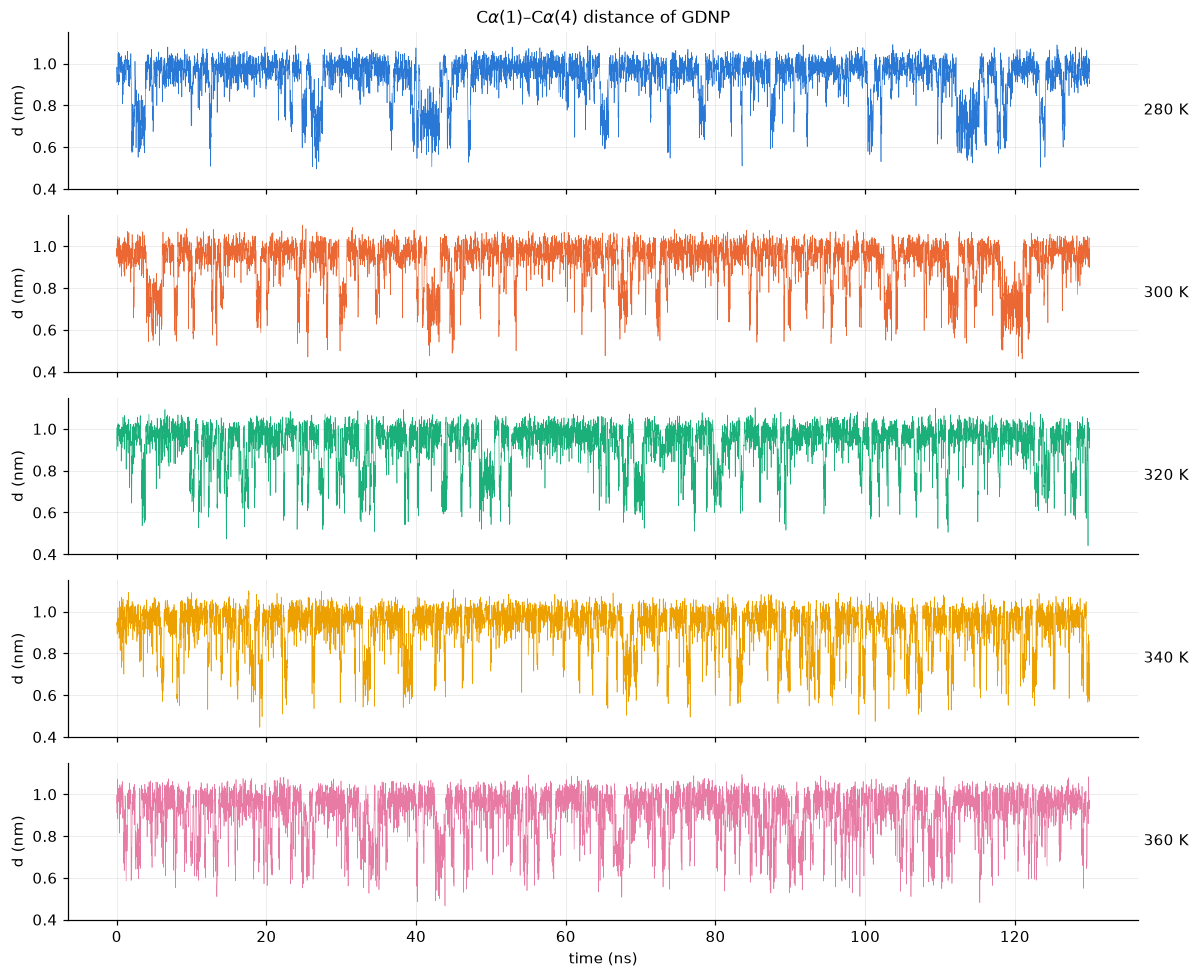

In [6]:
fig, axes = plt.subplots(len(TEMPS), 1, figsize=(11, 9), sharex=True, sharey=True)
for ax, (j, T) in zip(axes, enumerate(TEMPS)):
    ax.plot(t130, d130[:, j], color=T_COLOR[T], lw=0.4)
    ax.text(1.005, 0.5, f"{T} K", transform=ax.transAxes, va="center", fontsize=10)
    ax.set_ylim(0.4, 1.15)
    ax.set_ylabel("d (nm)")
axes[0].set_title(r"C$\alpha$(1)–C$\alpha$(4) distance of GDNP")
axes[-1].set_xlabel("time (ns)")
plt.tight_layout(); plt.show()

At this scale the trace looks like a dense band near 1 nm with **downward spikes**: the peptide
is mostly extended and every now and then folds briefly into a turn. Zoom in on a 3 ns window to
see that each spike is a proper excursion, lasting a few tens of picoseconds:

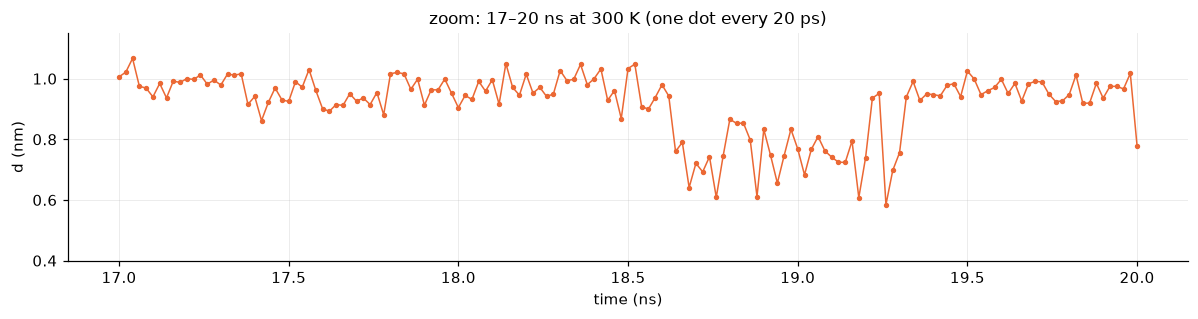

In [7]:
T_zoom, t0, t1 = 300, 17.0, 20.0
j = list(TEMPS).index(T_zoom)
sel = (t130 >= t0) & (t130 <= t1)

fig, ax = plt.subplots(figsize=(11, 3))
ax.plot(t130[sel], d130[sel, j], color=T_COLOR[T_zoom], lw=1, marker="o", ms=2.5)
ax.set_xlabel("time (ns)"); ax.set_ylabel("d (nm)"); ax.set_ylim(0.4, 1.15)
ax.set_title(f"zoom: {t0:g}–{t1:g} ns at {T_zoom} K (one dot every 20 ps)")
plt.tight_layout(); plt.show()

A time series is good for seeing *dynamics*; for *populations* a **histogram** is better. Below,
the distribution of the distance at each temperature, on a linear scale (left) and a
logarithmic one (right) — the log scale makes the rare, short-distance turn conformations visible:

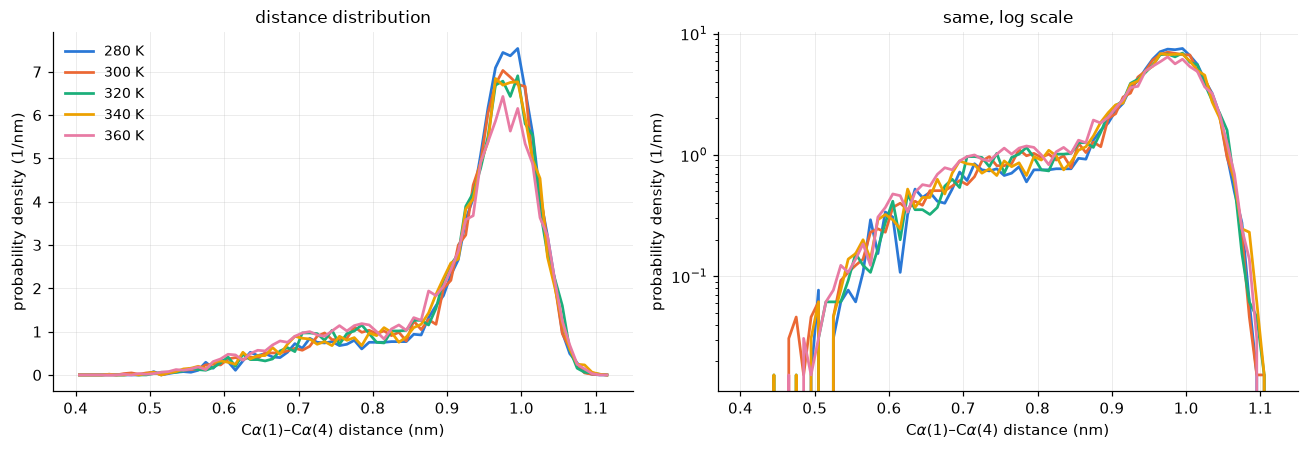

In [8]:
bins = np.arange(0.40, 1.13, 0.01)
centres = 0.5 * (bins[1:] + bins[:-1])

fig, (axL, axR) = plt.subplots(1, 2, figsize=(12, 4.2))
for j, T in enumerate(TEMPS):
    h, _ = np.histogram(d130[:, j], bins=bins, density=True)
    for ax in (axL, axR):
        ax.plot(centres, h, color=T_COLOR[T], lw=1.8, label=f"{T} K")
axR.set_yscale("log")
for ax, title in ((axL, "distance distribution"), (axR, "same, log scale")):
    ax.set_xlabel("C$\\alpha$(1)–C$\\alpha$(4) distance (nm)")
    ax.set_ylabel("probability density (1/nm)")
    ax.set_title(title)
axL.legend(loc="upper left")
plt.tight_layout(); plt.show()

---
## **5. Exercise 1 — where does the turn end?**

To count populations you need a **criterion**: a frame is a *turn* if its Cα(1)–Cα(4) distance is
below a cutoff, and *extended* otherwise.

**(a)** Look at the histograms above. Is there a clean gap between the two states — a distance
that the peptide (almost) never visits? Where does the extended peak end and where does the turn
region start?

**(b)** The classical structural definition of a β-turn (Lewis, Momany & Scheraga, 1973) is a
Cα(i)–Cα(i+3) distance **below 7 Å**. Is that consistent with what the histogram shows?

**(c)** Set `CUTOFF` (in nm) below and run the next two cells. The figure shades your turn region
and colours a stretch of trajectory by state — check that it captures the spikes you would call
"turns" by eye, and not the ordinary thermal wiggling of the extended state.

*Keep a note of your choice: in §8 you will see how much the final answer depends on it.*

In [9]:
# ---------- Exercise 1: your choice ----------
CUTOFF = 0.70            # <-- your choice: the turn/extended boundary in nm, e.g. CUTOFF = 0.xx

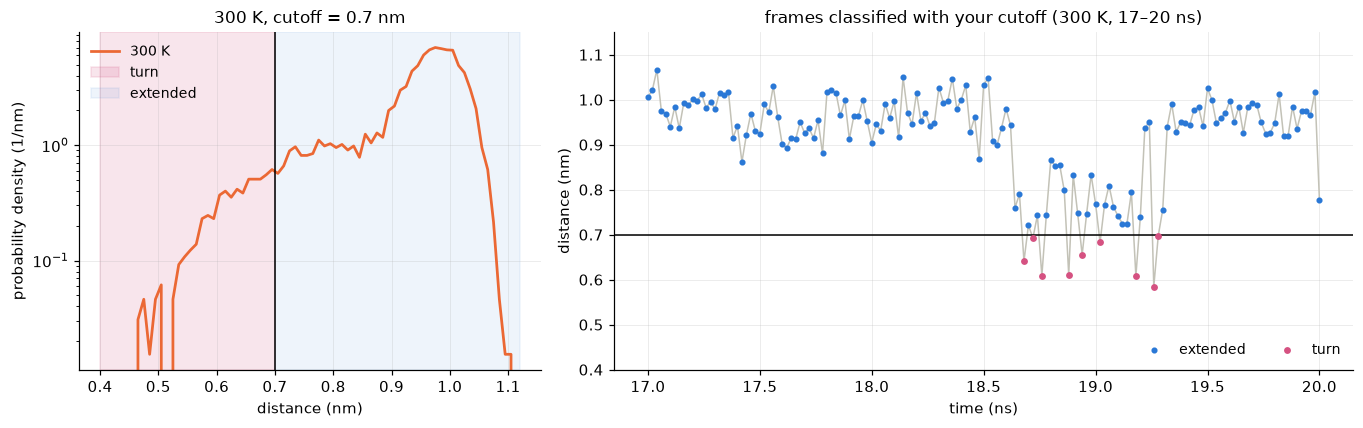

In [10]:
have_cutoff = isinstance(CUTOFF, (int, float)) and 0.3 < CUTOFF < 1.2

fig, (axH, axT) = plt.subplots(1, 2, figsize=(12.5, 4), gridspec_kw={"width_ratios": [1, 1.6]})
j = list(TEMPS).index(300)
h, _ = np.histogram(d130[:, j], bins=bins, density=True)
axH.plot(centres, h, color=T_COLOR[300], lw=1.8, label="300 K")
axH.set_yscale("log")
axH.set_xlabel("distance (nm)"); axH.set_ylabel("probability density (1/nm)")

sel = (t130 >= 17) & (t130 <= 20)
tt, dd = t130[sel], d130[sel, j]
axT.plot(tt, dd, color="#c3c2b7", lw=1)
if have_cutoff:
    axH.axvspan(bins[0], CUTOFF, color=C_TURN, alpha=0.15, label="turn")
    axH.axvspan(CUTOFF, bins[-1], color=C_EXT, alpha=0.08, label="extended")
    axH.axvline(CUTOFF, color="k", lw=1)
    turn = dd < CUTOFF
    axT.scatter(tt[~turn], dd[~turn], s=9, color=C_EXT, label="extended", zorder=3)
    axT.scatter(tt[turn], dd[turn], s=12, color=C_TURN, label="turn", zorder=3)
    axT.axhline(CUTOFF, color="k", lw=1)
    axH.set_title(f"300 K, cutoff = {CUTOFF:g} nm")
    axT.set_title(f"frames classified with your cutoff (300 K, 17–20 ns)")
    axT.legend(loc="lower right", ncol=2)
else:
    axH.set_title("300 K — no cutoff chosen yet")
    axT.set_title("300 K, 17–20 ns — no cutoff chosen yet")
axH.legend(loc="upper left")
axT.set_xlabel("time (ns)"); axT.set_ylabel("distance (nm)"); axT.set_ylim(0.4, 1.15)
plt.tight_layout(); plt.show()

if CUTOFF is None:
    print("Not yet: set CUTOFF (in nm) in the cell above and re-run both cells.")
elif not have_cutoff:
    print(f"CUTOFF = {CUTOFF!r} is not a distance in nm between 0.3 and 1.2. "
          "Type a plain number without quotes; if you were thinking in Å, divide by 10.")

<details open>
<summary><b>Exercise 1 — worked solution</b></summary>

**(a)** There is **no clean gap**. The extended state is a tall peak at 0.95–1.0 nm; below about
0.85 nm the distribution drops onto a broad, flat **shoulder** (0.65–0.85 nm) and then falls off
steeply towards the most compact turns at ≈0.45 nm. The density never goes to zero between the two
states: the peptide passes through every intermediate distance. Any cutoff is therefore a
*convention*, not a property of the data — which is why §8 checks how much it matters.

**(b)** Yes: **0.70 nm** sits in the lower part of the shoulder, well clear of the extended peak, so
a frame below it is unambiguously compact. It is also the standard β-turn definition, which makes
the results comparable with other studies — a good reason to prefer it over a value picked by eye.

**(c)** `CUTOFF = 0.70`. Everything quoted in the worked solutions below uses this value. Something
in **0.65–0.80 nm** is a defensible choice; much above 0.85 nm you start cutting into the extended
peak (counting thermal fluctuations of the extended chain as "turns"), much below 0.6 nm you only
keep the most compact turns and throw away most of the turn population.

Look again at the zoom on the right: between 18.6 and 19.3 ns the peptide is compact the whole
time, but its distance **flickers across 0.70 nm**, so a single cutoff chops one turn episode into
many short ones. For *populations* this does not matter — we only count frames — but it would if you
wanted to count folding *events* or measure lifetimes (see §12, kinetics).
</details>

---
## **6. Exercise 2 — from populations to $\Delta G$**

**(a)** Write `turn_fraction(d, cutoff)`: given a 1-D numpy array `d` of distances (one per frame),
return the **fraction of frames that are a turn**, i.e. $P_\text{turn}$.
*(Hint: `d < cutoff` is an array of `True`/`False`, and `True` counts as 1.)*

**(b)** Complete `delta_G(p_turn, T)` — only its `return` line is missing: the folding free energy in **kJ/mol** from
$\Delta G = -RT\ln\left(P_\text{turn}/P_\text{extended}\right)$. In a two-state model
$P_\text{extended} = 1 - P_\text{turn}$. Use numpy functions (`np.log`) so that it also works when
`p_turn` is an array — you will need that in Exercise 4.

The self-check below tells you when both are right — and, if not, it tries to tell you *what* is
wrong. The cell after it then applies your functions to every temperature.

In [11]:
# ---------- Exercise 2: complete the two functions ----------
R = 8.314462618e-3        # gas constant in kJ/(mol K)

def turn_fraction(d, cutoff):
    '''(a) fraction of the frames in d (1-D array of distances in nm) that are a turn.'''
    return np.mean(np.asarray(d) < cutoff)

def delta_G(p_turn, T):
    '''(b) folding free energy (kJ/mol) from the turn population at temperature T (K).
       Must also work when p_turn is a numpy array.'''
    p_turn = np.asarray(p_turn, dtype=float)
    return -R * T * np.log(p_turn / (1 - p_turn))

In [12]:
# ---------- self-check ----------
ok = lambda got, want: "OK" if np.allclose(got, want, atol=1e-3) else f"<- expected {want}"

print("(a) turn_fraction")
test_d = np.array([0.5, 0.6, 0.8, 0.9])
if works(turn_fraction, test_d, 0.7):
    f = float(np.mean(turn_fraction(test_d, 0.7)))
    if np.isclose(f, 0.5):
        print(f"    [0.5, 0.6, 0.8, 0.9] with cutoff 0.7 -> {f:.3f}   OK")
    elif np.isclose(f, 2):
        print(f"    got {f:g}: that is the NUMBER of turn frames; divide by the number of frames "
              "(or use np.mean) to get the FRACTION")
    else:
        print(f"    [0.5, 0.6, 0.8, 0.9] with cutoff 0.7 -> {f:.3f}   <- expected 0.5 (two of the four are < 0.7)")
else:
    print("    not yet: replace the placeholder")

print("(b) delta_G")
if works(delta_G, 0.1, 300):
    v = float(np.mean(delta_G(0.1, 300)))
    RT = R * 300
    diagnosis = [(5.481, "OK"),
                 (-5.481, "<- check the sign: dG = -RT ln K"),
                 (5481.0, "<- units: use R in kJ/(mol K) (as defined above), not J/(mol K)"),
                 (-RT * np.log(0.1), "<- use the ratio P_turn / P_extended, not P_turn alone"),
                 (-RT * np.log10(1/9), "<- np.log10 is base 10: use np.log (natural logarithm)"),
                 (-RT * np.log(9), "<- you used P_extended / P_turn: turn the ratio upside down")]
    msg = next((m for want, m in diagnosis if np.isclose(v, want, atol=1e-2)), "<- expected +5.481")
    print(f"    P_turn = 0.1, 300 K -> {v:+.3f} kJ/mol   {msg}")
    if msg == "OK":
        print(f"    P_turn = 0.5, 300 K -> {float(delta_G(0.5, 300)):+.3f} kJ/mol   {ok(delta_G(0.5, 300), 0.0)}")
        print(f"    P_turn = 0.9, 360 K -> {float(delta_G(0.9, 360)):+.3f} kJ/mol   {ok(delta_G(0.9, 360), -6.577)}")
        try:
            arr = delta_G(np.array([0.1, 0.5]), 300)
            print(f"    works on arrays     -> {np.round(arr, 3)}   "
                  f"{'OK' if np.shape(arr) == (2,) else '<- should return one value per element'}")
        except TypeError:
            print("    does not work on arrays: use np.log (numpy), not math.log")
else:
    print("    not yet: replace the placeholder")

try:      # Exercise 2 counts as done only when both functions pass the checks above
    ex2_ok = (np.isclose(float(np.mean(turn_fraction(test_d, 0.7))), 0.5)
              and np.allclose(delta_G(np.array([0.1, 0.5]), 300), [5.481, 0.0], atol=1e-3))
except Exception:
    ex2_ok = False

(a) turn_fraction
    [0.5, 0.6, 0.8, 0.9] with cutoff 0.7 -> 0.500   OK
(b) delta_G
    P_turn = 0.1, 300 K -> +5.481 kJ/mol   OK
    P_turn = 0.5, 300 K -> -0.000 kJ/mol   OK
    P_turn = 0.9, 360 K -> -6.577 kJ/mol   OK
    works on arrays     -> [ 5.481 -0.   ]   OK


In [13]:
DG = None     # array of dG, one per temperature
if not have_cutoff:
    print("Not yet: choose a CUTOFF in Exercise 1.")
elif not ex2_ok:
    print("Not yet: turn_fraction() and delta_G() must pass the self-check in the cell above.")
else:
    print(f"cutoff {CUTOFF:g} nm")
    print(f"{'T (K)':>6} {'frames':>7} {'turn':>6} {'P_turn':>8} {'K':>8} {'dG (kJ/mol)':>12}")
    dgs = []
    for j, T in enumerate(TEMPS):
        p = turn_fraction(d130[:, j], CUTOFF)
        dgs.append(float(delta_G(p, T)))
        print(f"{T:>6} {len(d130):>7} {int(round(p*len(d130))):>6} {p:>8.4f} {p/(1-p):>8.4f} {dgs[-1]:>12.2f}")
    DG = np.array(dgs)

cutoff 0.7 nm
 T (K)  frames   turn   P_turn        K  dG (kJ/mol)
   280    6501    356   0.0548   0.0579         6.63
   300    6501    392   0.0603   0.0642         6.85
   320    6501    350   0.0538   0.0569         7.63
   340    6501    424   0.0652   0.0698         7.53
   360    6501    494   0.0760   0.0822         7.48


**(c)** Is folding favourable at any of the five temperatures? Roughly what percentage of the time
is GDNP a turn?

**(d)** Does $\Delta G$ change *systematically* with temperature? Does any temperature look out of line?

<details open>
<summary><b>Exercise 2 — worked solution</b></summary>

```python
def turn_fraction(d, cutoff):
    return np.mean(np.asarray(d) < cutoff)

def delta_G(p_turn, T):
    p_turn = np.asarray(p_turn, dtype=float)
    return -R * T * np.log(p_turn / (1 - p_turn))
```

With `CUTOFF = 0.70` nm:

| T (K) | $P_\text{turn}$ | $K$ | $\Delta G$ (kJ/mol) |
|---|---|---|---|
| 280 | 0.0548 | 0.0579 | 6.63 |
| 300 | 0.0603 | 0.0642 | 6.85 |
| 320 | 0.0538 | 0.0569 | 7.63 |
| 340 | 0.0652 | 0.0698 | 7.53 |
| 360 | 0.0760 | 0.0822 | 7.48 |

**(c)** No: $\Delta G$ is **positive at every temperature** (+6.6 to +7.6 kJ/mol). GDNP is a turn
only about **5–8 % of the time** — the turn is a real but minority conformation. Note that a few
kJ/mol, i.e. a few $RT$ ($RT = 2.5$ kJ/mol at 300 K), is all it takes to make a state rare.

**(d)** The trend is upwards — $\Delta G$ rises with temperature (yet the turn population still *grows*, from 5.5 to 7.6 %: what sets the population is $\Delta G/RT$, see Exercise 3) — but it is
not smooth: **320 K** stands out (7.63, higher than both 340 and 360 K). That jump is about as
large as the whole trend between 280 and 360 K: a first hint that the statistical
error on each point is *not* small (Exercise 4 and §10 quantify it).
</details>

---
## **7. Exercise 3 — enthalpy and entropy of folding**

**(a)** Write `fit_dH_dS(T, dG)`: fit the straight line $\Delta G = \Delta H - T\Delta S$ through
the points and return **`(dH, dS)`** — $\Delta H$ in kJ/mol and $\Delta S$ in kJ/(mol K). You may use
`np.polyfit(x, y, 1)`, which returns `(slope, intercept)`; mind the **sign** of $\Delta S$.

**(b)** Run the figure cell. How well do the five points follow a straight line?

**(c)** What are the signs of $\Delta H$ and $\Delta S$? Is folding of GDNP driven by enthalpy, by
entropy, or by neither? Give a molecular interpretation of each sign.

**(d)** At what temperature would turn and extended be **equally populated** ($\Delta G = 0$)?

In [14]:
# ---------- Exercise 3: complete the function ----------
def fit_dH_dS(T, dG):
    '''(a) straight-line fit of dG = dH - T*dS.
       Returns (dH in kJ/mol, dS in kJ/(mol K)).'''
    slope, intercept = np.polyfit(T, dG, 1)
    return intercept, -slope

In [15]:
# ---------- self-check on made-up data:  dG = 12 - 0.03 T  (i.e. dH = 12, dS = 0.03) ----------
T_test = np.array([280, 300, 320, 340, 360])
ex3_ok = works(fit_dH_dS, T_test, 12 - 0.03 * T_test)
if ex3_ok:
    dH, dS = fit_dH_dS(T_test, 12 - 0.03 * T_test)
    if abs(dH - 12) < 1e-6 and abs(dS - 0.03) < 1e-9:
        print(f"dH = {dH:.4f} kJ/mol   OK\ndS = {dS:.4f} kJ/(mol K)   OK")
    elif abs(dS - 12) < 1e-6 or abs(dS + 12) < 1e-6:
        print("dH and dS look swapped: np.polyfit returns (slope, intercept), in that order.")
        ex3_ok = False
    else:
        print(f"dH = {dH:.4f} kJ/mol   {'OK' if abs(dH - 12) < 1e-6 else '<- expected 12 (dH is the intercept)'}")
        hint = ("<- check the sign: dG = dH - T dS, so the slope is MINUS dS" if abs(dS + 0.03) < 1e-9 else
                "<- keep dS in kJ/(mol K): do not multiply by 1000" if abs(abs(dS) - 30) < 1e-6 else
                "<- expected 0.03")
        print(f"dS = {dS:.4f} kJ/(mol K)   {hint}")
        ex3_ok = False
else:
    print("Not yet: replace the placeholder in fit_dH_dS().")

dH = 12.0000 kJ/mol   OK
dS = 0.0300 kJ/(mol K)   OK


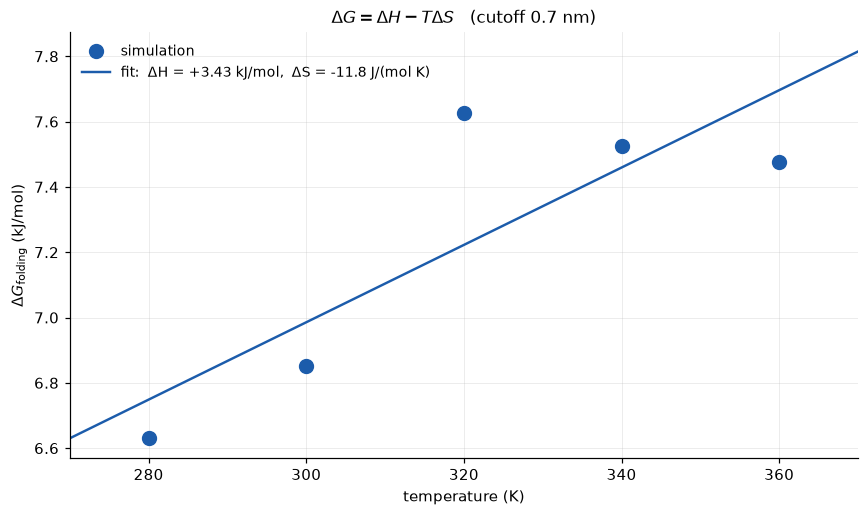

Fit with standard errors (from the scatter of the points around the line):
   dH = +3.43 +- 1.46 kJ/mol,   dS = -11.8 +- 4.5 J/(mol K)


In [16]:
if DG is None:
    print("Not yet: Exercises 1 and 2 must be completed first.")
else:
    fig, ax = plt.subplots(figsize=(8, 4.8))
    Tline = np.linspace(270, 370, 2)
    ax.plot(TEMPS, DG, "o", color=C_RUN, ms=9, label="simulation", zorder=3)
    if ex3_ok:
        dH, dS = fit_dH_dS(TEMPS, DG)
        ax.plot(Tline, dH - Tline * dS, color=C_RUN, lw=1.6,
                label=f"fit:  ΔH = {dH:+.2f} kJ/mol,  ΔS = {1000*dS:+.1f} J/(mol K)")
    ax.set_xlim(270, 370)
    ax.set_xlabel("temperature (K)"); ax.set_ylabel(r"$\Delta G_\mathrm{folding}$ (kJ/mol)")
    ax.set_title(rf"$\Delta G = \Delta H - T\Delta S$   (cutoff {CUTOFF:g} nm)")
    ax.legend(loc="upper left")
    plt.tight_layout(); plt.show()

    if not ex3_ok:
        print("Complete fit_dH_dS() to add the fitted lines.")
    else:
        (s, i), cov = np.polyfit(TEMPS, DG, 1, cov=True)
        print("Fit with standard errors (from the scatter of the points around the line):")
        print(f"   dH = {i:+.2f} +- {np.sqrt(cov[1,1]):.2f} kJ/mol,"
              f"   dS = {-1000*s:+.1f} +- {1000*np.sqrt(cov[0,0]):.1f} J/(mol K)")

<details open>
<summary><b>Exercise 3 — worked solution</b></summary>

```python
def fit_dH_dS(T, dG):
    slope, intercept = np.polyfit(T, dG, 1)
    return intercept, -slope          # dG = dH - T dS  ->  slope = -dS
```

**(b)** With `CUTOFF = 0.70` nm: $\Delta H = +3.43 \pm 1.46$ kJ/mol and
$\Delta S = -11.8 \pm 4.5$ J mol⁻¹ K⁻¹. The points follow the line only roughly — 320 K sits well
above it — so the fitted values carry sizeable uncertainties. Where that scatter comes from, and
how large the *real* statistical error is, is the subject of Exercise 4 and §10. (Note how big the
error on $\Delta H$ is:
it is an *extrapolation* to $T = 0$, 280 K away from the nearest data point, so any error in the
slope is multiplied by ≈300 in the intercept.)

**(c)** $\Delta S < 0$: forming a turn **costs entropy**. That is expected — the turn is one specific
compact arrangement, the extended chain can take many. More surprising, $\Delta H$ comes out
**slightly positive** (≈ +3 kJ/mol, but only about two standard errors from zero): forming the turn
does not even gain enthalpy. In water, the hydrogen bond and contacts that stabilise the turn
largely *replace* equally good hydrogen bonds to water molecules, so there is little or no net
enthalpic gain. With $\Delta H \gtrsim 0$ and $\Delta S < 0$, **neither** term favours folding — which
is why the turn is a minority state at every temperature. *(How sure can we be of these signs? The
error bars quoted here only measure how far the five points scatter from a line; §10
computes proper statistical errors — and finds them larger.)*

**(d)** $\Delta G = 0$ when $T = \Delta H / \Delta S$. With $\Delta H > 0$ and $\Delta S < 0$ that is a
*negative* temperature: **never**. The turn is a minority state at any temperature; heating makes
it slightly more populated but never dominant. That is not a contradiction with $\Delta G$ rising with
$T$: the population follows $\ln K = -\Delta G/RT = -\Delta H/RT + \Delta S/R$, and with $\Delta H > 0$ the
first term shrinks on heating. (Within the error
bars $\Delta H$ could be slightly negative, which would give a $T_m$ — but far below 0 °C, where water
would be ice.)
</details>

---
## **8. How much does the answer depend on your cutoff?**

In Exercise 1 you made a choice that the data did not dictate. A good analysis checks whether its
conclusions survive a different, equally reasonable choice. The cell below repeats Exercises 2 and
3 for **every cutoff from 0.55 to 0.85 nm** using your own functions, and marks your
choice. No new code to write — but look carefully at the result.

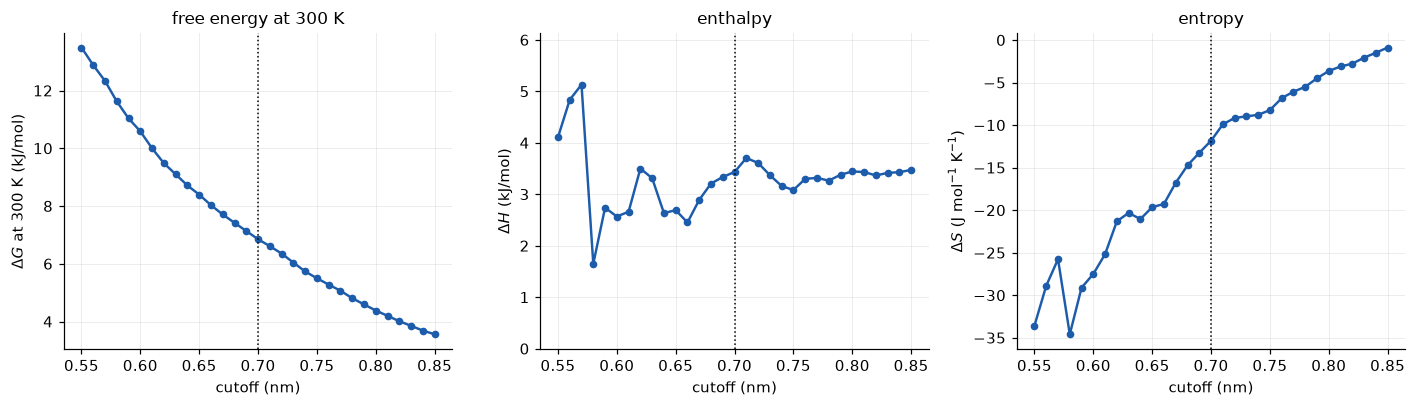

 cutoff   dG300      dH  dS (J/mol/K)
   0.55   13.49    4.11         -33.6
   0.60   10.59    2.57         -27.5
   0.65    8.40    2.69         -19.6
   0.70    6.85    3.43         -11.8
   0.75    5.50    3.08          -8.2
   0.80    4.38    3.44          -3.6
   0.85    3.56    3.47          -0.9


In [17]:
if not (ex2_ok and ex3_ok):
    print("Not yet: complete Exercises 2 and 3 first.")
else:
    cutoffs = np.round(np.arange(0.55, 0.851, 0.01), 3)
    scan = []
    for c in cutoffs:
        dgs = [float(delta_G(turn_fraction(d130[:, j], c), T)) for j, T in enumerate(TEMPS)]
        scan.append((*fit_dH_dS(TEMPS, np.array(dgs)), dgs[list(TEMPS).index(300)]))
    scan = np.array(scan)

    fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), sharex=True)
    panels = ((scan[:, 2], r"$\Delta G$ at 300 K (kJ/mol)", "free energy at 300 K"),
              (scan[:, 0], r"$\Delta H$ (kJ/mol)", "enthalpy"),
              (1000 * scan[:, 1], r"$\Delta S$ (J mol$^{-1}$ K$^{-1}$)", "entropy"))
    for ax, (y, lab, title) in zip(axes, panels):
        ax.plot(cutoffs, y, "o-", color=C_RUN, ms=4)
        if have_cutoff:
            ax.axvline(CUTOFF, color="k", lw=1, ls=":")
        ax.set_xlabel("cutoff (nm)"); ax.set_ylabel(lab); ax.set_title(title)
    axes[1].set_ylim(min(0, scan[:, 0].min() - 1), scan[:, 0].max() + 1)
    plt.tight_layout(); plt.show()

    print(f"{'cutoff':>7} {'dG300':>7} {'dH':>7} {'dS (J/mol/K)':>13}")
    for c, (dH, dS, g) in zip(cutoffs, scan):
        if round(c * 100) % 5 == 0:
            print(f"{c:>7.2f} {g:>7.2f} {dH:>7.2f} {1000*dS:>13.1f}")

**Questions.** Which of the three quantities depends strongly on the cutoff, and which hardly at
all? Why should the *entropy* in particular depend on where you put the boundary of the turn state?
Which conclusions of Exercise 3 are robust, and which numbers should you only report together with
the definition used?

<details open>
<summary><b>Discussion</b></summary>

$\Delta G$ at 300 K falls steadily as the cutoff grows (10.6 kJ/mol at 0.60 nm, 6.9 at 0.70 nm, 4.4
at 0.80 nm) — of course: a larger cutoff counts more frames as turn. That change is almost
**entirely entropic**: $\Delta S$ goes from about −28 to −4 J mol⁻¹ K⁻¹ while $\Delta H$ stays within
roughly +2.5 to +3.5 kJ/mol over the same range.

That is exactly what statistical mechanics predicts. Widening the turn region adds conformations to
the "turn" state, and if those conformations have about the same energy as the ones already in it,
they add **microstates, not energy** — the state's entropy grows ($S = k\ln W$), its enthalpy barely
moves. The entropy of a state is a property of *how you define the state*.

Robust *to the choice of cutoff*: $\Delta G > 0$ at all temperatures, $\Delta S < 0$, $\Delta H$ small
and positive (whether they are robust to the *statistical* error is §10). Not robust:
the actual values of $\Delta G$ and $\Delta S$ — report them **together with the criterion** (here:
Cα(i)–Cα(i+3) < 0.70 nm). This is true of every population-based free energy from simulations, and
also of experiments, which each "see" folding through their own observable.
</details>

---
## **9. Exercise 4 — how long is long enough?**

An MD estimate is only as good as its sampling. Each temperature lets us watch an estimate
*being made*: compute $\Delta G$ from the first 1 ns, the first 2 ns, … the first
130 ns, and look at how it settles.

**(a)** Write `running_dG(d, T, cutoff)`: return an array of the same length as `d` whose element
`k` is $\Delta G$ computed from frames `0 … k` only. Re-use your `delta_G()`.
The idea, on a tiny example with frames *turn, extended, turn, turn*:

| frames seen | 1 | 2 | 3 | 4 |
|---|---|---|---|---|
| turn frames so far (`np.cumsum`) | 1 | 1 | 2 | 3 |
| running $P_\text{turn}$ | 1/1 | 1/2 | 2/3 | 3/4 |

*(At the very start $P_\text{turn}$ may be 0 or 1, which gives $\Delta G = \pm\infty$ and a
warning — that is fine, the plots skip those points.)*

**(b)** From the figure: after how many nanoseconds does each running $\Delta G$ stay within
±0.5 kJ/mol of its final value? Would a simulation half as long (65 ns) have been enough?

**(c)** Do $\Delta H$ and $\Delta S$ converge faster or slower than the individual $\Delta G$ values? Why?

In [18]:
# ---------- Exercise 4: complete the function ----------
def running_dG(d, T, cutoff):
    '''(a) element k = dG (kJ/mol) estimated from frames 0..k of the distance array d.'''
    n_turn = np.cumsum(np.asarray(d) < cutoff)
    p_turn = n_turn / np.arange(1, len(d) + 1)
    with np.errstate(divide="ignore"):
        return delta_G(p_turn, T)

In [19]:
# ---------- self-check ----------
ex4_ok = False
if not (have_cutoff and ex2_ok):
    print("Not yet: complete Exercises 1 and 2 first.")
else:
    with np.errstate(divide="ignore", invalid="ignore"):
        try:
            test = np.asarray(running_dG(np.array([0.5, 0.9, 0.9, 0.5]), 300, 0.7), dtype=float)
        except Exception as err:
            test = None
            print("running_dG raised:", repr(err))
        want = delta_G(np.array([1.0, 0.5, 1/3, 0.5]), 300)
    if test is None or np.isnan(test).all():
        print("Not yet: replace the placeholder in running_dG().")
    elif test.shape != want.shape:
        print(f"Not quite: running_dG should return one value per frame (an array of length {len(want)}), "
              f"got shape {test.shape}. Did you use np.mean (one number) instead of np.cumsum (a running sum)?")
    elif not np.allclose(test[1:], want[1:]):
        print(f"Not quite: for [0.5, 0.9, 0.9, 0.5] at 300 K (cutoff 0.7) expected "
              f"[-inf, {want[1]:.3f}, {want[2]:.3f}, {want[3]:.3f}], got {np.round(test, 3)}")
    else:
        j = list(TEMPS).index(300)
        last = running_dG(d130[:, j], 300, CUTOFF)[-1]
        full = delta_G(turn_fraction(d130[:, j], CUTOFF), 300)
        ex4_ok = bool(np.isclose(last, full))
        print(f"OK on the test series; last element at 300 K = {last:.3f} kJ/mol "
              f"{'= the full-run value, OK' if ex4_ok else f'<- should equal {float(full):.3f}'}")

OK on the test series; last element at 300 K = 6.850 kJ/mol = the full-run value, OK


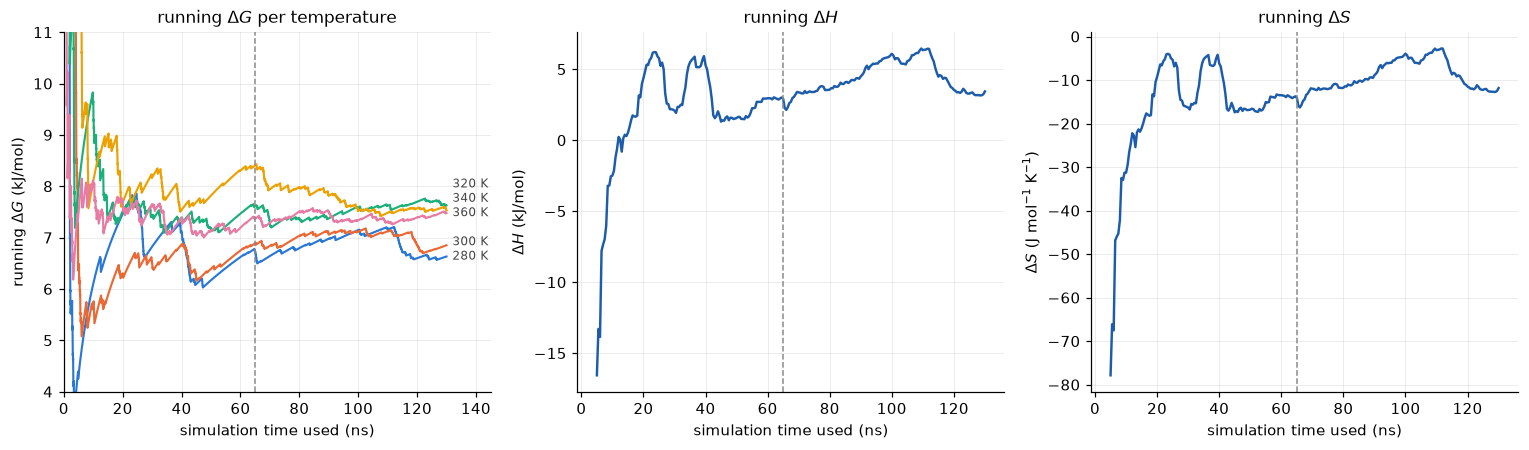

time after which the running dG stays within +-0.5 kJ/mol of its 130 ns value:
   280 K:  112.6 ns
   300 K:   49.2 ns
   320 K:   53.2 ns
   340 K:   73.6 ns
   360 K:   10.4 ns

dG after half the run (65 ns, dashed line) vs after 130 ns:
   280 K:   6.73  vs   6.63   (difference +0.10)
   300 K:   6.89  vs   6.85   (difference +0.04)
   320 K:   7.61  vs   7.63   (difference -0.02)
   340 K:   8.41  vs   7.53   (difference +0.88)
   360 K:   7.37  vs   7.48   (difference -0.10)


In [20]:
if not ex4_ok:
    print("Not yet: complete running_dG() above.")
else:
    with np.errstate(divide="ignore", invalid="ignore"):
        RUN = np.array([running_dG(d130[:, j], T, CUTOFF) for j, T in enumerate(TEMPS)])
    RUN[~np.isfinite(RUN)] = np.nan

    fig, axes = plt.subplots(1, 3, figsize=(14, 4.2))
    ax = axes[0]
    ylab = {}                                   # direct labels, nudged apart so they do not overlap
    for j in np.argsort(RUN[:, -1]):
        y = RUN[j, -1]
        ylab[j] = max(y, max(ylab.values(), default=-np.inf) + 0.28)
    for j, T in enumerate(TEMPS):
        ax.plot(t130, RUN[j], color=T_COLOR[T], lw=1.4, label=f"{T} K")
        ax.text(t130[-1] + 2, ylab[j], f"{T} K", va="center", fontsize=8, color="#444444")
    ax.set_ylim(4, 11); ax.set_xlim(0, 145)
    ax.set_ylabel(r"running $\Delta G$ (kJ/mol)"); ax.set_title(r"running $\Delta G$ per temperature")

    if ex3_ok:
        idx = np.searchsorted(t130, np.arange(5, 130.01, 0.5))
        fits = np.array([fit_dH_dS(TEMPS, RUN[:, k]) if np.all(np.isfinite(RUN[:, k]))
                         else (np.nan, np.nan) for k in idx])
        axes[1].plot(t130[idx], fits[:, 0], color=C_RUN, lw=1.6)
        axes[2].plot(t130[idx], 1000 * fits[:, 1], color=C_RUN, lw=1.6)
    axes[1].set_ylabel(r"$\Delta H$ (kJ/mol)"); axes[1].set_title(r"running $\Delta H$")
    axes[2].set_ylabel(r"$\Delta S$ (J mol$^{-1}$ K$^{-1}$)"); axes[2].set_title(r"running $\Delta S$")
    for ax in axes:
        ax.axvline(65, color=C_REF, ls="--", lw=1)
        ax.set_xlabel("simulation time used (ns)")
    plt.tight_layout(); plt.show()

    print("time after which the running dG stays within +-0.5 kJ/mol of its 130 ns value:")
    for j, T in enumerate(TEMPS):
        outside = np.where(~(np.abs(RUN[j] - RUN[j, -1]) <= 0.5))[0]
        print(f"   {T} K: {t130[outside[-1] + 1] if len(outside) else 0:6.1f} ns")
    print("\ndG after half the run (65 ns, dashed line) vs after 130 ns:")
    k65 = np.searchsorted(t130, 65)
    for j, T in enumerate(TEMPS):
        print(f"   {T} K: {RUN[j, k65]:6.2f}  vs {RUN[j, -1]:6.2f}   (difference {RUN[j, k65] - RUN[j, -1]:+.2f})")
    if not ex3_ok:
        print("Complete fit_dH_dS() (Exercise 3) to add the running dH and dS.")

<details open>
<summary><b>Exercise 4 — worked solution</b></summary>

```python
def running_dG(d, T, cutoff):
    n_turn = np.cumsum(np.asarray(d) < cutoff)            # turn frames seen so far
    p_turn = n_turn / np.arange(1, len(d) + 1)           # running P_turn
    with np.errstate(divide="ignore"):                   # P_turn = 0 at the start -> +inf
        return delta_G(p_turn, T)
```

**(b)** With `CUTOFF = 0.70` nm the running $\Delta G$ curves swing by several kJ/mol in the first
10–20 ns and only slowly settle. The ±0.5 kJ/mol criterion is reached after roughly
**10 ns at 360 K, ≈50 ns at 300 and 320 K, ≈74 ns at 340 K and ≈113 ns at 280 K** — so for
some temperatures only **well after half the run**. Half the simulation would not have been
enough: at 65 ns the 340 K estimate (8.41) is still 0.9 kJ/mol above its final value, which would
have made 340 K, not 320 K, the outlier. Even at 130 ns the curves are still drifting by a
few tenths of a kJ/mol: an honest error bar is needed (§10).

**(c)** **Slower**, and much more noisily — especially $\Delta H$. Each fit combines five independent
$\Delta G$ estimates, and their errors do not average out in a slope: a 0.5 kJ/mol error at one end of
an 80 K range changes the slope by ≈6 J mol⁻¹ K⁻¹, and that slope error is multiplied by ≈300 K in
the intercept $\Delta H$. Derived quantities are always noisier than the measurements they come from;
the running $\Delta H$ only stabilises around +3 kJ/mol in the second half of the run.

</details>

---
## **10. Error bars by block averaging**

Exercise 4 showed that the $\Delta G$ values carry a statistical error. You cannot get it from the
frame-to-frame spread: a turn lasts a few tens of picoseconds, longer than the 20 ps between
frames, and the peptide sometimes stays compact for nanoseconds, so consecutive frames are
**correlated**, not independent. The standard trick is
**block averaging**: cut the trajectory into $n$ consecutive blocks, measure $P_\text{turn}$ in each,
and treat the blocks as $n$ repeated experiments. The standard error of the mean is then

$$\sigma_{P} \;\approx\; \frac{\mathrm{sd}(P_1,\dots,P_n)}{\sqrt{n}} .$$

This only works if the blocks are **longer than the correlation time**, so that they really are
independent. Too many (short) blocks and you *under*estimate the error; too few and the error
estimate itself becomes very noisy.

*(Why average $P_\text{turn}$ and not $\Delta G$ per block? A short block may contain no turn at all,
giving $\Delta G=+\infty$; and because the logarithm is non-linear, the average of per-block
$\Delta G$'s is biased. So we average the populations and convert the error at the end.)*

The error on $P_\text{turn}$ is converted into an error on $\Delta G$ by **error propagation**. Since
$\Delta G = -RT\left[\ln P - \ln(1-P)\right]$,

$$\frac{\mathrm{d}\Delta G}{\mathrm{d}P} = -RT\left[\frac1P + \frac1{1-P}\right] = -\frac{RT}{P(1-P)}
\qquad\Longrightarrow\qquad
\sigma_{\Delta G} = \frac{RT}{P(1-P)}\,\sigma_P .$$

Note what this means: for a *rare* state ($P$ small) a given absolute error on $P$ becomes a large
error on $\Delta G$ — rare states are expensive to measure.

The two functions below implement block averaging and the error propagation. There is no code to
write in this section: run the cells, look at the figures and **answer the questions**. The section
uses your `CUTOFF` if you have set it, and 0.70 nm otherwise.

In [21]:
R_GAS = 8.314462618e-3                         # gas constant in kJ/(mol K)
cut = CUTOFF if have_cutoff else 0.70          # your cutoff from Exercise 1, or 0.70 nm


def block_fractions(d, cutoff, n_blocks):
    '''Split d into n_blocks consecutive blocks; return the turn fraction of each block.'''
    fractions = []
    for block in np.array_split(np.asarray(d), n_blocks):
        fractions.append(np.mean(block < cutoff))
    return np.array(fractions)

def dG_error(p_turn, sem_p, T):
    '''Error on dG (kJ/mol) caused by an error sem_p on the turn fraction p_turn.'''
    return R_GAS * T * sem_p / (p_turn * (1 - p_turn))


# example: 300 K in 10 blocks of 13 ns
j = list(TEMPS).index(300)
P_blocks = block_fractions(d130[:, j], cut, 10)
print(f"cutoff {cut:g} nm, 300 K, turn fraction in each of 10 blocks of 13 ns:")
print("   ", np.round(P_blocks, 3))
print(f"    mean {P_blocks.mean():.4f}, standard error {np.std(P_blocks, ddof=1)/np.sqrt(10):.4f}"
      f"  ->  error on dG = {dG_error(P_blocks.mean(), np.std(P_blocks, ddof=1)/np.sqrt(10), 300):.2f} kJ/mol")

cutoff 0.7 nm, 300 K, turn fraction in each of 10 blocks of 13 ns:
    [0.091 0.049 0.045 0.098 0.014 0.049 0.04  0.063 0.045 0.109]
    mean 0.0603, standard error 0.0095  ->  error on dG = 0.42 kJ/mol


How many blocks should we use? The figure shows the resulting error on $\Delta G$ as a function of
the block length, for every temperature:

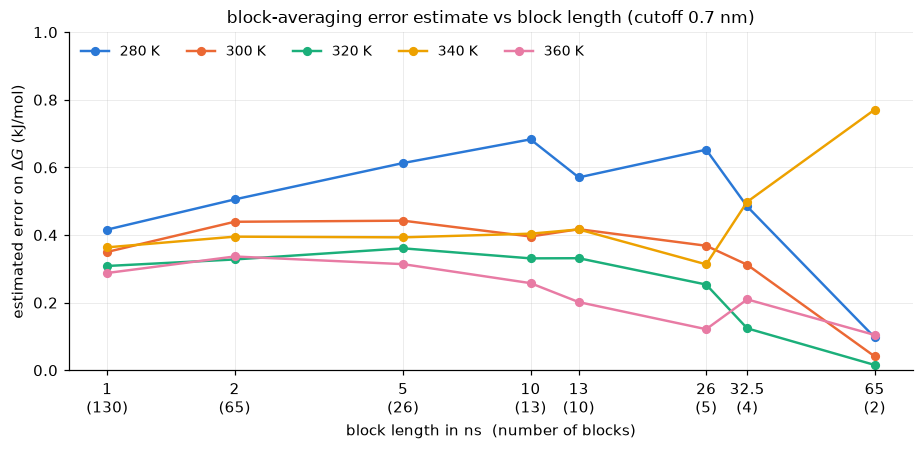

In [22]:
n_list = [130, 65, 26, 13, 10, 5, 4, 2]
fig, ax = plt.subplots(figsize=(8.5, 4.2))
for j, T in enumerate(TEMPS):
    p = np.mean(d130[:, j] < cut)
    err = [dG_error(p, np.std(block_fractions(d130[:, j], cut, n), ddof=1) / np.sqrt(n), T)
           for n in n_list]
    ax.plot(130 / np.array(n_list), err, "o-", color=T_COLOR[T], ms=5, label=f"{T} K")
ax.set_xscale("log")
ax.set_xticks(130 / np.array(n_list)); ax.minorticks_off()
ax.set_xticklabels([f"{130/n:g}\n({n})" for n in n_list])
ax.set_xlabel("block length in ns  (number of blocks)")
ax.set_ylabel(r"estimated error on $\Delta G$ (kJ/mol)")
ax.set_title(f"block-averaging error estimate vs block length (cutoff {cut:g} nm)")
ax.legend(ncol=5, loc="upper left"); ax.set_ylim(0, 1.0)
plt.tight_layout(); plt.show()

**Questions — how long should a block be?**

**(a)** In the figure, why is the error estimate smallest for the shortest blocks? Should you trust
it there?

**(b)** Go back to **Exercise 4 (§9, "how long is long enough?")**. For each temperature, note after
how many nanoseconds the running $\Delta G$ settled within ±0.5 kJ/mol of its final value. That time
tells you how long the slowest fluctuations of the population last at that temperature. A block can
only act as an *independent* repeat of the experiment if it is at least that long. What is the
**shortest acceptable block length at each temperature**, and how many such blocks fit into 130 ns?

**(c)** Compare your answer to (b) with the figure: at which temperatures does the error estimate
stop growing (reach a plateau) within the block lengths shown, and at which does it not? Which
temperature's error bar do you trust most, and which least?

**(d)** Choose `N_BLOCKS` in the cell below (a whole number; the block length is 130/`N_BLOCKS` ns)
and re-run the next cell. Explain your choice. The default is 10 blocks of 13 ns.

In [23]:
N_BLOCKS = 10            # number of blocks to cut the 130 ns run into -- your choice, question (d)

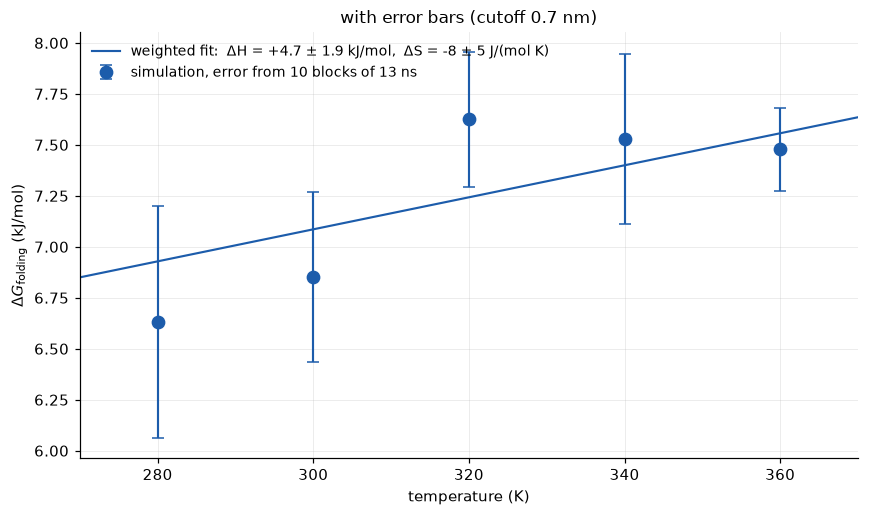

 T (K)      dG     +-
   280    6.63   0.57
   300    6.85   0.42
   320    7.63   0.33
   340    7.53   0.42
   360    7.48   0.20

(weighted fit, each point weighted by 1/error)
dH = +4.73 +- 1.85 kJ/mol      (2.6 standard errors from 0)
dS = -7.9 +- 5.5 J/(mol K)   (1.4 standard errors from 0)


In [24]:
P_all = np.array([np.mean(d130[:, j] < cut) for j in range(len(TEMPS))])
G_all = -R_GAS * TEMPS * np.log(P_all / (1 - P_all))
err = np.array([dG_error(P_all[j], np.std(block_fractions(d130[:, j], cut, N_BLOCKS), ddof=1)
                         / np.sqrt(N_BLOCKS), T) for j, T in enumerate(TEMPS)])
(s, i), cov = np.polyfit(TEMPS, G_all, 1, w=1/err, cov="unscaled")
dH, dS, sH, sS = i, -s, np.sqrt(cov[1, 1]), np.sqrt(cov[0, 0])

fig, ax = plt.subplots(figsize=(8, 4.8))
Tline = np.linspace(270, 370, 2)
ax.errorbar(TEMPS, G_all, yerr=err, fmt="o", color=C_RUN, ms=8, capsize=4, lw=1.4,
            label=f"simulation, error from {N_BLOCKS} blocks of {130/N_BLOCKS:.3g} ns")
ax.plot(Tline, dH - Tline * dS, color=C_RUN, lw=1.4,
        label=f"weighted fit:  ΔH = {dH:+.1f} ± {sH:.1f} kJ/mol,  "
              f"ΔS = {1000*dS:+.0f} ± {1000*sS:.0f} J/(mol K)")
ax.set_xlim(270, 370)
ax.set_xlabel("temperature (K)"); ax.set_ylabel(r"$\Delta G_\mathrm{folding}$ (kJ/mol)")
ax.set_title(f"with error bars (cutoff {cut:g} nm)")
ax.legend(loc="upper left")
plt.tight_layout(); plt.show()

print(f"{'T (K)':>6} {'dG':>7} {'+-':>6}")
for T, g, e in zip(TEMPS, G_all, err):
    print(f"{T:>6} {g:>7.2f} {e:>6.2f}")
print(f"\n(weighted fit, each point weighted by 1/error)")
print(f"dH = {dH:+.2f} +- {sH:.2f} kJ/mol      ({abs(dH)/sH:.1f} standard errors from 0)")
print(f"dS = {1000*dS:+.1f} +- {1000*sS:.1f} J/(mol K)   ({abs(dS)/sS:.1f} standard errors from 0)")

**Questions — what do the error bars tell you?**

**(e)** Is the jump you noticed in Exercise 2 (320 K) real, or is it within the error bars?

**(f)** Is $\Delta H$ significantly different from zero? Is $\Delta S$? (A common rule of thumb: a
value is significant when it is more than two standard errors away from zero.)

**(g)** In view of your answer to (c): are these error bars more likely to be too large or too
small? What does that mean for your answer to (f)?

<details open>
<summary><b>Discussion</b></summary>

**(a)** Short blocks are shorter than the slow fluctuations visible in the trajectories (at 280 K the
peptide sometimes stays compact for several ns), so neighbouring blocks are correlated rather than
independent, and their spread *under*estimates the true error.

**(b)** With `CUTOFF = 0.70` nm, Exercise 4 gave settling times of about **113 ns (280 K), 49 ns
(300 K), 53 ns (320 K), 74 ns (340 K) and 10 ns (360 K)**. Taken as the minimum block length, that
leaves roughly **12 blocks at 360 K, 2 at 300 and 320 K, and only 1 at 280 and 340 K** — and you
need at least a few blocks to compute a standard deviation at all. So with 130 ns, proper block
averaging is only really possible at 360 K, where the peptide folds and unfolds most often.
(The settling time is a generous criterion, the actual correlation time is shorter, but it shows
the right trend: the colder the system, the slower it decorrelates.)

**(c)** From 300 to 360 K the curves are roughly flat from a few ns on; at **280 K** the estimate
keeps growing up to ≈10 ns blocks, with no clear plateau before the curve becomes too noisy
(2–5 blocks). Together with (b): the 360 K error bar is the most trustworthy, the 280 K one the
least — and 340 K, flat as its curve looks, also needed a long time to settle in Exercise 4, so
its error bar deserves some suspicion too. A flat curve is necessary, not sufficient.

**(d)** **10 blocks of 13 ns** is a compromise: long enough to be past the steep rise at most
temperatures, while keeping enough blocks for a meaningful standard deviation. Anything from 5 to
13 ns per block is defensible — but (b) says that at 280 and 340 K even 13 ns is too short.

**(e)** With 10 blocks the errors are **0.2–0.6 kJ/mol** (0.57 at 280 K down to 0.20 at 360 K) — as
large as the differences between neighbouring temperatures. The 320 K "outlier" is **noise**, not
physics (and Exercise 4 showed that halfway through the run it was 340 K that looked odd; §11 looks
at this more closely).

**(f)** The weighted fit gives $\Delta H = +4.7 \pm 1.9$ kJ/mol (2.6 standard errors from zero) and
$\Delta S = -8 \pm 6$ J mol⁻¹ K⁻¹ (1.4 standard errors): $\Delta H$ is marginally significant,
**the sign of $\Delta S$ is not established**. Note also how much the central values moved from
the unweighted fit of Exercise 3 (+3.4 and −12): the precise 360 K point now pulls harder.

**(g)** Too **small**, at least at the colder temperatures (blocks shorter than the slow
fluctuations, see (b) and (c)). So $\Delta H$ and $\Delta S$ are even *less* certain than the
weighted fit suggests. What these data robustly say is that $\Delta G > 0$ — the turn is a
minority state — at every temperature; splitting $\Delta G$ into $\Delta H$ and $\Delta S$ needs
considerably more sampling (longer runs, more temperatures, or both).
</details>

---
## **11. Is 320 K an outlier?**

In the $\Delta G(T)$ plot of Exercise 3, the 320 K point sits well above the line through the
other four. It is tempting to call it an **outlier**, leave it out and refit. The cell below does
exactly that, in two ways:

* **unweighted** — the fit of Exercise 3, whose uncertainties come only from how far the points
  scatter around the line;
* **weighted** — the fit of §10, with each point's block-averaging error bar.

It is self-contained (it does not need your exercise functions); it uses your `CUTOFF` (0.70 nm
if you have not set one) and the `N_BLOCKS` of §10. Change `LEAVE_OUT` to test
another temperature.

cutoff 0.7 nm, error bars from 10 blocks

       fit           points    dH (kJ/mol)    dS (J/mol/K)  dS / its error
unweighted            all 5   +3.43 +- 1.46   -11.8 +-  4.5           2.6
unweighted    without 320 K   +3.33 +- 0.75   -11.8 +-  2.3           5.1
  weighted            all 5   +4.73 +- 1.85    -7.9 +-  5.5           1.4
  weighted    without 320 K   +3.76 +- 1.98   -10.4 +-  5.8           1.8

320 K lies +0.53 kJ/mol from the weighted line through the other points = +1.6 times its own error bar.
chi^2 of the weighted fit through all 5 points: 2.2 for 3 degrees of freedom (a good fit has chi^2 ~ dof).


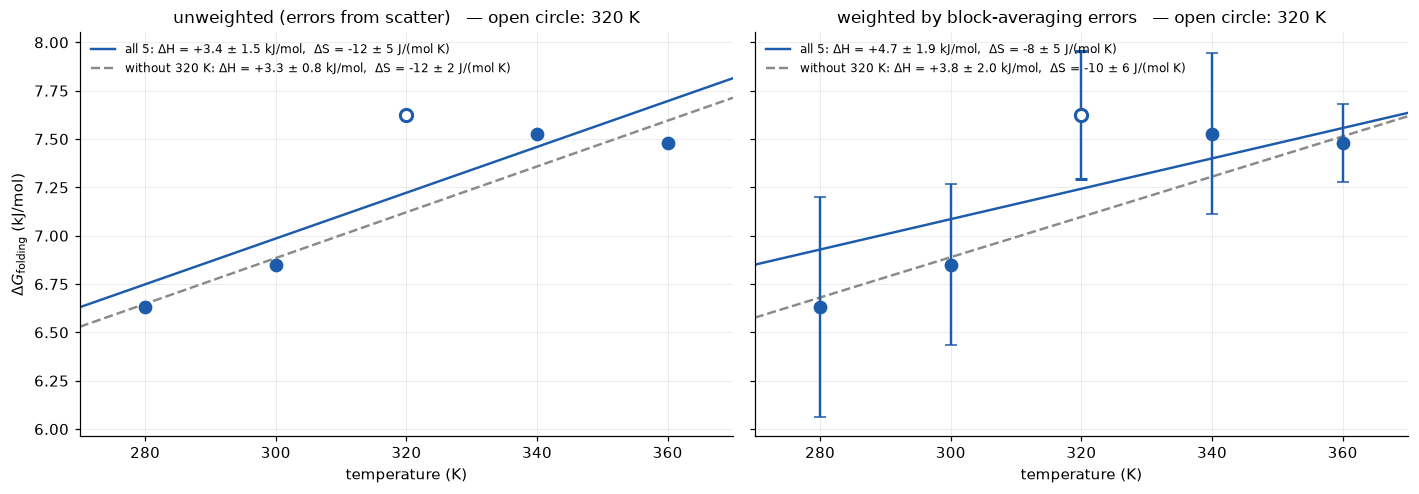

In [25]:
LEAVE_OUT = 320          # K: the temperature to treat as an outlier

R_GAS = 8.314462618e-3   # kJ/(mol K)
cut = CUTOFF if have_cutoff else 0.70
nbl = N_BLOCKS if isinstance(N_BLOCKS, int) and 2 <= N_BLOCKS <= 130 else 10

Tf = TEMPS.astype(float)
P = np.array([np.mean(d130[:, j] < cut) for j in range(len(TEMPS))])
G = -R_GAS * Tf * np.log(P / (1 - P))
sigma = np.array([R_GAS * T * np.std([np.mean(b < cut) for b in np.array_split(d130[:, j], nbl)], ddof=1)
                  / np.sqrt(nbl) / (P[j] * (1 - P[j])) for j, T in enumerate(Tf)])
keep = TEMPS != LEAVE_OUT

def line_fit(mask, weighted):
    if weighted:
        (s, i), cov = np.polyfit(Tf[mask], G[mask], 1, w=1/sigma[mask], cov="unscaled")
    else:
        (s, i), cov = np.polyfit(Tf[mask], G[mask], 1, cov=True)
    return dict(dH=i, sH=np.sqrt(cov[1, 1]), dS=-s, sS=np.sqrt(cov[0, 0]), s=s, i=i,
                chi2=np.sum(((G[mask] - (i + s*Tf[mask])) / sigma[mask])**2), dof=mask.sum() - 2)

fits = {(w, m): line_fit(mask, w) for w in (False, True)
        for m, mask in (("all 5", np.ones(len(TEMPS), bool)), (f"without {LEAVE_OUT} K", keep))}

print(f"cutoff {cut:g} nm, error bars from {nbl} blocks\n")
print(f"{'fit':>10} {'points':>16} {'dH (kJ/mol)':>14} {'dS (J/mol/K)':>15}  {'dS / its error':>14}")
for (w, m), f in fits.items():
    print(f"{'weighted' if w else 'unweighted':>10} {m:>16} {f['dH']:+7.2f} +- {f['sH']:4.2f} "
          f"{1000*f['dS']:+7.1f} +- {1000*f['sS']:4.1f}  {abs(f['dS'])/f['sS']:>12.1f}")

f4 = fits[True, f"without {LEAVE_OUT} K"]
jx = list(TEMPS).index(LEAVE_OUT)
dev = G[jx] - (f4["i"] + f4["s"] * LEAVE_OUT)
print(f"\n{LEAVE_OUT} K lies {dev:+.2f} kJ/mol from the weighted line through the other points "
      f"= {dev/sigma[jx]:+.1f} times its own error bar.")
fa = fits[True, "all 5"]
print(f"chi^2 of the weighted fit through all 5 points: {fa['chi2']:.1f} for {fa['dof']} degrees of freedom "
      f"(a good fit has chi^2 ~ dof).")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.6), sharey=True)
Tline = np.linspace(270, 370, 2)
for ax, w in zip(axes, (False, True)):
    if w:
        ax.errorbar(Tf[keep], G[keep], yerr=sigma[keep], fmt="o", color=C_RUN, ms=8, capsize=4, zorder=3)
        ax.errorbar(Tf[~keep], G[~keep], yerr=sigma[~keep], fmt="o", color=C_RUN, mfc="white", mew=2,
                    ms=8, capsize=4, zorder=3)
    else:
        ax.plot(Tf[keep], G[keep], "o", color=C_RUN, ms=8, zorder=3)
        ax.plot(Tf[~keep], G[~keep], "o", color=C_RUN, mfc="white", mew=2, ms=8, zorder=3)
    for m, ls, col in (("all 5", "-", C_RUN), (f"without {LEAVE_OUT} K", "--", C_REF)):
        f = fits[w, m]
        ax.plot(Tline, f["dH"] - Tline * f["dS"], ls=ls, color=col, lw=1.6,
                label=f"{m}: ΔH = {f['dH']:+.1f} ± {f['sH']:.1f} kJ/mol,  ΔS = {1000*f['dS']:+.0f} ± {1000*f['sS']:.0f} J/(mol K)")
    ax.set_xlim(270, 370); ax.set_xlabel("temperature (K)")
    ax.set_title(("weighted by block-averaging errors" if w else "unweighted (errors from scatter)")
                 + f"   — open circle: {LEAVE_OUT} K")
    ax.legend(loc="upper left", fontsize=8)
axes[0].set_ylabel(r"$\Delta G_\mathrm{folding}$ (kJ/mol)")
plt.tight_layout(); plt.show()

**Questions.** (a) In the *unweighted* fit, what happens to the uncertainties of $\Delta H$ and
$\Delta S$ when 320 K is removed? Is $\Delta S$ now "significant"? (b) What happens in the *weighted*
fit? (c) How many of its own error bars is 320 K away from the line through the other four, and how
surprising is that for one point out of five? (d) Is it legitimate to drop it?

<details open>
<summary><b>Discussion</b></summary>

With `CUTOFF = 0.70` nm and 10 blocks:

| fit | points | $\Delta H$ (kJ/mol) | $\Delta S$ (J mol⁻¹ K⁻¹) |
|---|---|---|---|
| unweighted | all 5 | +3.43 ± 1.46 | −11.8 ± 4.5 |
| unweighted | without 320 K | +3.33 ± 0.75 | −11.8 ± 2.3 |
| weighted | all 5 | +4.73 ± 1.85 | −7.9 ± 5.5 |
| weighted | without 320 K | +3.76 ± 1.98 | −10.4 ± 5.8 |

**(a)** The central values hardly move, but the unweighted uncertainties **halve**: $\Delta S$ goes
from 2.6 to 5 standard errors from zero and suddenly looks rock solid. That is an illusion. The
unweighted errors only measure how well the *remaining* points line up — and we just removed the
point that did not line up. Four points that happen to sit on a line say nothing about how
precisely each of them is known.

**(b)** The weighted fit, which uses the real statistical errors, barely changes: $\Delta H$ and
$\Delta S$ move by about half an error bar, and their uncertainties stay the same (they even grow a
little — fewer points). $\Delta S$ remains under two standard errors from zero.

**(c)** 320 K lies **0.53 kJ/mol, i.e. 1.6 error bars**, above the line through the others. For
five independent points, the chance that *at least one* is that far off by pure chance is about
40 %. And the weighted fit through all five points has $\chi^2 \approx 2.2$ for 3 degrees of
freedom — a perfectly normal fit. There is no statistical evidence that 320 K is anything special.
(Recall Exercise 4, too: halfway through the run it was 340 K that looked like the outlier.)

**(d)** No. Dropping a point *because it does not fit* is cherry-picking: it makes the result look
more precise without making it more correct. Legitimate reasons to exclude data are independent of
the result — a simulation that crashed, was not equilibrated, or used a wrong setting. The honest
summary is the weighted fit through all five points, error bars included.
</details>

---
## **12. Kinetics: how fast does GDNP fold and unfold?**

So far we have only counted *how much* time the peptide spends in each state. The same trajectory
also tells us *how long each visit lasts*, and that gives the **kinetics**:

* the mean time spent in the turn before unfolding, $\tau_\text{turn}$, gives the unfolding rate
  $k_u = 1/\tau_\text{turn}$;
* the mean time spent extended before folding again, $\tau_\text{ext}$, gives the folding rate
  $k_f = 1/\tau_\text{ext}$.

Two checks connect kinetics to thermodynamics:

1. **Detailed balance**: at equilibrium $K = k_f/k_u = \tau_\text{turn}/\tau_\text{ext}$, which must
   agree with the population ratio $P_\text{turn}/P_\text{ext}$ from the counting.
2. **Arrhenius**: $k = A\,e^{-E_a/RT}$, so $\ln k$ against $1/T$ is a straight line with slope
   $-E_a/R$. The difference between the activation energies of folding and unfolding is the
   folding enthalpy: $\Delta H = E_{a,f} - E_{a,u}$.

**A catch: how do you decide when a visit ends?** With a single cutoff, every time the distance
flickers across it counts as a new visit (you saw this in the zoom of Exercise 1). The cell below
therefore compares two ways of assigning states:

* **single cutoff**: turn whenever $d <$ `TURN_BELOW`;
* **transition-based** ("core-to-core"): the peptide counts as folded once $d$ drops below
  `TURN_BELOW`, and stays folded until $d$ rises above `EXT_ABOVE`. In between it keeps the state
  it came from, so brief excursions across one line no longer count as new visits.

The cell is self-contained (it does not need your exercise functions). Change the two thresholds
at the top and re-run to see how robust the rates are.

single cutoff  (turn < 0.7 nm)
 T (K)  visits  1-frame   tau_turn   tau_ext      k_u     k_f  K kinetic  K counted
                              (ps)      (ns)   (1/ns)  (1/ns)
   280     197      55%         36      0.60    27.67    1.67     0.0602     0.0579
   300     250      64%         31      0.47    31.89    2.14     0.0672     0.0642
   320     240      70%         29      0.51    34.29    1.98     0.0577     0.0569
   340     279      65%         30      0.42    32.90    2.36     0.0716     0.0698
   360     329      69%         30      0.36    33.30    2.76     0.0829     0.0822

transition-based  (turn < 0.7 nm, extended > 0.85 nm)
 T (K)  visits  1-frame   tau_turn   tau_ext      k_u     k_f  K kinetic  K counted
                              (ps)      (ns)   (1/ns)  (1/ns)
   280      76      13%        201      1.46     4.97    0.69     0.1380     0.1334
   300      96       6%        187      1.12     5.35    0.89     0.1674     0.1603
   320     119      18%        137

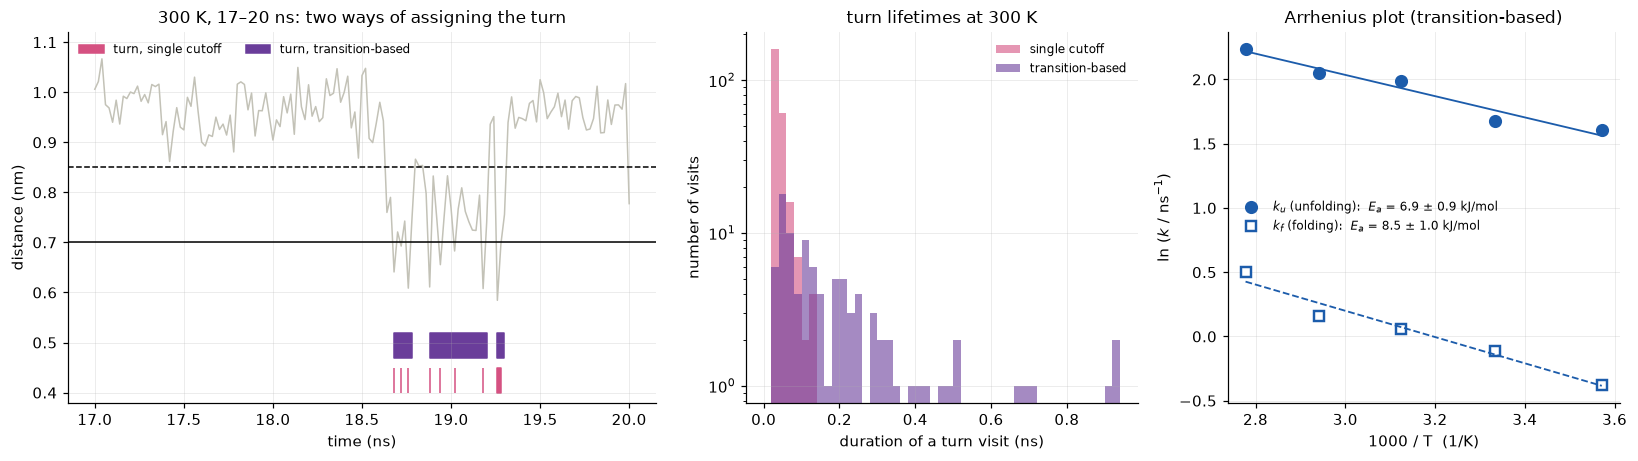

In [26]:
TURN_BELOW = 0.70        # nm: below this the peptide is (or becomes) a turn
EXT_ABOVE  = 0.85        # nm: above this it is (or becomes) extended  -- transition-based only

R_GAS = 8.314462618e-3  # kJ/(mol K)
dt = t130[1] - t130[0]   # ns between frames


def assign_single(x):
    return x < TURN_BELOW

def assign_transition_based(x):
    '''Turn from the moment x drops below TURN_BELOW until it rises above EXT_ABOVE.'''
    state = np.empty(len(x), dtype=bool)
    current = x[0] < TURN_BELOW
    for i, v in enumerate(x):
        if v < TURN_BELOW:
            current = True
        elif v > EXT_ABOVE:
            current = False
        state[i] = current
    return state

def dwell_times(state):
    '''Durations (ns) of the consecutive turn and extended visits. The first and the last visit
       are dropped: they are cut off by the start and end of the simulation.'''
    edges = np.flatnonzero(np.diff(state.astype(int))) + 1
    visits = np.split(state, edges)[1:-1]
    lengths = np.array([len(v) for v in visits]) * dt
    is_turn = np.array([v[0] for v in visits], dtype=bool)
    return lengths[is_turn], lengths[~is_turn]


kin = {}
for method, assign in (("single cutoff", assign_single), ("transition-based", assign_transition_based)):
    rows = []
    for j, T in enumerate(TEMPS):
        state = assign(d130[:, j])
        tau_turn, tau_ext = dwell_times(state)
        rows.append(dict(T=T, n=len(tau_turn), tau_turn=tau_turn.mean(), tau_ext=tau_ext.mean(),
                         one_frame=np.mean(tau_turn < 1.5 * dt), all_turn=tau_turn,
                         K_pop=state.mean() / (1 - state.mean())))
    kin[method] = rows

for method, rows in kin.items():
    print(f"{method}  (turn < {TURN_BELOW:g} nm" +
          (f", extended > {EXT_ABOVE:g} nm)" if method != "single cutoff" else ")"))
    print(f"{'T (K)':>6} {'visits':>7} {'1-frame':>8} {'tau_turn':>10} {'tau_ext':>9} {'k_u':>8} {'k_f':>7}"
          f" {'K kinetic':>10} {'K counted':>10}")
    print(f"{'':>6} {'':>7} {'':>8} {'(ps)':>10} {'(ns)':>9} {'(1/ns)':>8} {'(1/ns)':>7}")
    for r in rows:
        print(f"{r['T']:>6} {r['n']:>7} {r['one_frame']:>8.0%} {1000*r['tau_turn']:>10.0f} "
              f"{r['tau_ext']:>9.2f} {1/r['tau_turn']:>8.2f} {1/r['tau_ext']:>7.2f} "
              f"{r['tau_turn']/r['tau_ext']:>10.4f} {r['K_pop']:>10.4f}")
    print()

# ---------- Arrhenius fits ----------
invT = 1 / TEMPS.astype(float)
Ea = {}
for method, rows in kin.items():
    for label, key in (("unfolding", "tau_turn"), ("folding", "tau_ext")):
        k = 1 / np.array([r[key] for r in rows])
        (slope, icpt), cov = np.polyfit(invT, np.log(k), 1, cov=True)
        Ea[method, label] = (-slope * R_GAS, np.sqrt(cov[0, 0]) * R_GAS, slope, icpt, k)
for method in kin:
    eu, su = Ea[method, "unfolding"][:2]
    ef, sf = Ea[method, "folding"][:2]
    print(f"{method:>17}:  Ea(unfolding) = {eu:4.1f} +- {su:3.1f},  Ea(folding) = {ef:4.1f} +- {sf:3.1f},"
          f"  Ea,f - Ea,u = {ef - eu:+.1f} kJ/mol")

# ---------- figure ----------
fig, axes = plt.subplots(1, 3, figsize=(15, 4.3), gridspec_kw={"width_ratios": [1.5, 1, 1]})
j300 = list(TEMPS).index(300)
sel = (t130 >= 17) & (t130 <= 20)
x = d130[:, j300]
ax = axes[0]
ax.plot(t130[sel], x[sel], color="#c3c2b7", lw=1)
ax.fill_between(t130[sel], 0.40, 0.45, where=assign_single(x)[sel], step="mid", color=C_TURN,
                label="turn, single cutoff")
ax.fill_between(t130[sel], 0.47, 0.52, where=assign_transition_based(x)[sel], step="mid",
                color="#6a3d9a", label="turn, transition-based")
ax.axhline(TURN_BELOW, color="k", lw=1); ax.axhline(EXT_ABOVE, color="k", lw=1, ls="--")
ax.set_ylim(0.38, 1.12); ax.set_xlabel("time (ns)"); ax.set_ylabel("distance (nm)")
ax.set_title("300 K, 17–20 ns: two ways of assigning the turn")
ax.legend(loc="upper left", fontsize=8, ncol=2)

ax = axes[1]
bins_t = np.arange(0, max(kin["transition-based"][j300]["all_turn"].max(), 0.2) + 0.04, 0.02)
for method, col in (("single cutoff", C_TURN), ("transition-based", "#6a3d9a")):
    ax.hist(kin[method][j300]["all_turn"], bins=bins_t, color=col, alpha=0.6, label=method)
ax.set_yscale("log"); ax.set_xlabel("duration of a turn visit (ns)"); ax.set_ylabel("number of visits")
ax.set_title("turn lifetimes at 300 K"); ax.legend(fontsize=8)

ax = axes[2]
xx = np.linspace(invT.min(), invT.max(), 2)
for label, mk in (("unfolding", "o"), ("folding", "s")):
    eu, su, slope, icpt, k = Ea["transition-based", label]
    ax.plot(1000 * invT, np.log(k), mk, color=C_RUN, ms=7, mfc="white" if label == "folding" else C_RUN,
            mew=1.6, label=f"$k_{{{label[0]}}}$ ({label}):  $E_a$ = {eu:.1f} ± {su:.1f} kJ/mol")
    ax.plot(1000 * xx, icpt + slope * xx, color=C_RUN, lw=1.2, ls="--" if label == "folding" else "-")
ax.set_xlabel("1000 / T  (1/K)"); ax.set_ylabel(r"$\ln\,(k\ /\ \mathrm{ns}^{-1})$")
ax.set_title("Arrhenius plot (transition-based)"); ax.legend(fontsize=8, loc="center left")
plt.tight_layout(); plt.show()

**Questions.** (a) Why are the single-cutoff turn lifetimes meaningless? (b) Does detailed balance
hold? (c) Which process is faster, folding or unfolding, and which speeds up more with temperature?
Does $E_{a,f}-E_{a,u}$ agree with the $\Delta H$ you found from the populations? (d) Why is the
transition-based $K$ larger than the one you counted with a single cutoff in Exercise 2?

<details open>
<summary><b>Discussion</b></summary>

With `TURN_BELOW = 0.70`, `EXT_ABOVE = 0.85` nm:

**(a)** With a single cutoff, **55–70 % of all turn visits last exactly one frame** (20 ps) and the
median visit is one frame: the "lifetime" (≈30 ps) mostly measures how often the distance flickers
across 0.70 nm, and how often we saved a frame. Sample more often and it would shrink further. The
transition-based assignment merges most of those flickers into longer episodes (left panel): 76–182 turn visits
per temperature (instead of 200–330), lasting **≈100–200 ps** on average, while the extended state
lives **≈0.6–1.5 ns** between turns. Note that for the *populations* (Exercises 2–5) the flicker
did not matter: a frame is counted wherever it falls. It is the *kinetics* that need a careful
definition of when a transition has really happened.

**(b)** Yes: $\tau_\text{turn}/\tau_\text{ext}$ agrees with the counted population ratio to within
a few % at every temperature, for both assignments. That is detailed balance — the rates and
the populations are two views of the same equilibrium.

**(c)** Unfolding ($k_u \approx 5$–9 ns⁻¹) is faster than folding ($k_f \approx 0.7$–1.7
ns⁻¹), roughly 6–7× faster — that ratio *is* the small $K$. Both speed up with temperature, with low barriers of
**6.9 ± 0.9 kJ/mol (unfolding) and 8.5 ± 1.0 kJ/mol (folding)**, i.e. only ≈3 $RT$: GDNP is not separated by a
large barrier, it diffuses in and out of the turn. $E_{a,f}-E_{a,u} \approx +1.6$ kJ/mol is small
and positive, consistent within its (large) error with the small positive $\Delta H$ of Exercise 3
and §10 — kinetics and thermodynamics tell the same story.

**(d)** Because the state definition changed: in the transition-based assignment the frames between
0.70 and 0.85 nm that follow a turn are counted as *turn*. $K$ (and therefore $\Delta G$) depends on
where the boundaries are drawn — exactly the lesson of §8. Compare like with like.
</details>

---
## **13. Take-home messages**

* **Counting is thermodynamics.** A well-sampled MD trajectory is a sample of the Boltzmann
  distribution; the fraction of time spent in a state *is* its probability, and
  $\Delta G = -RT\ln(P_\text{turn}/P_\text{extended})$ follows directly.
* **$\Delta G(T)$ gives $\Delta H$ and $\Delta S$**: the slope is $-\Delta S$, the intercept $\Delta H$
  (assuming $\Delta C_p \approx 0$). For GDNP the turn is present only ≈5–8 % of the time
  ($\Delta G > 0$ at every temperature); $\Delta H$ comes out small and positive, $\Delta S$ small and
  negative — but only just outside their error bars.
* **States are defined by you.** There is no gap in the distance distribution; the cutoff is a
  convention, and the entropy of a state depends on how widely it is drawn. Report it with the result.
* **Sampling sets the error.** Consecutive frames are correlated; what counts is the number of
  *independent events*, which only grows with simulation length.
  Block averaging turns this into an error bar.
* **Kinetics need a careful definition of a transition.** With a single cutoff, flicker across
  the line looks like hundreds of extra folding events; a transition-based assignment recovers the
  real ≈0.1–0.2 ns turn lifetimes. The rates obey detailed balance ($k_f/k_u = K$) and their
  activation energies are only a few $RT$.
* **Don't drop inconvenient points.** Removing the "outlier" at 320 K makes the unweighted fit look
  twice as precise, but the honest, error-weighted fit barely changes: the point is only 1.6σ off.
* **Derived quantities are noisier.** $\Delta H$, an extrapolation to $T=0$, has a much larger
  relative error than any individual $\Delta G$. A result without an error bar is not a result.

## **Going further**

Open-ended, no scaffolding provided:

* **van 't Hoff plot.** Plot $\ln K$ against $1/T$: the slope is $-\Delta H/R$. Do you get the same
  $\Delta H$ as from the $\Delta G(T)$ fit? (You should — it is the same equation rearranged.)
* **Kinetics and the sampling interval.** Keep only every 2nd or 5th frame (`d130[::5]`) and
  redo §12 with both assignments. Which rates change, and why?
* **Error bars on the rates.** Use block averaging (§10) on the dwell times to put error
  bars on the Arrhenius plot of §12. Is $E_{a,f}-E_{a,u}$ significantly different from zero?
* **Curvature.** Fit a parabola to $\Delta G(T)$ instead of a line. A non-zero curvature would mean a
  heat capacity change $\Delta C_p$. Is the curvature significant given the error bars of §10?
* **Equilibration.** The simulations start from an extended structure. Does discarding the first
  5 or 10 ns change any of your results?